# Figure 1 updates
- Reviewer 1 suggested boxes instead of lines for better visual distinction -- perhaps possible with "hist" call?
- Consider the plotting regions more carefully -- why should figure 2 not overlap with the area of figure 3?

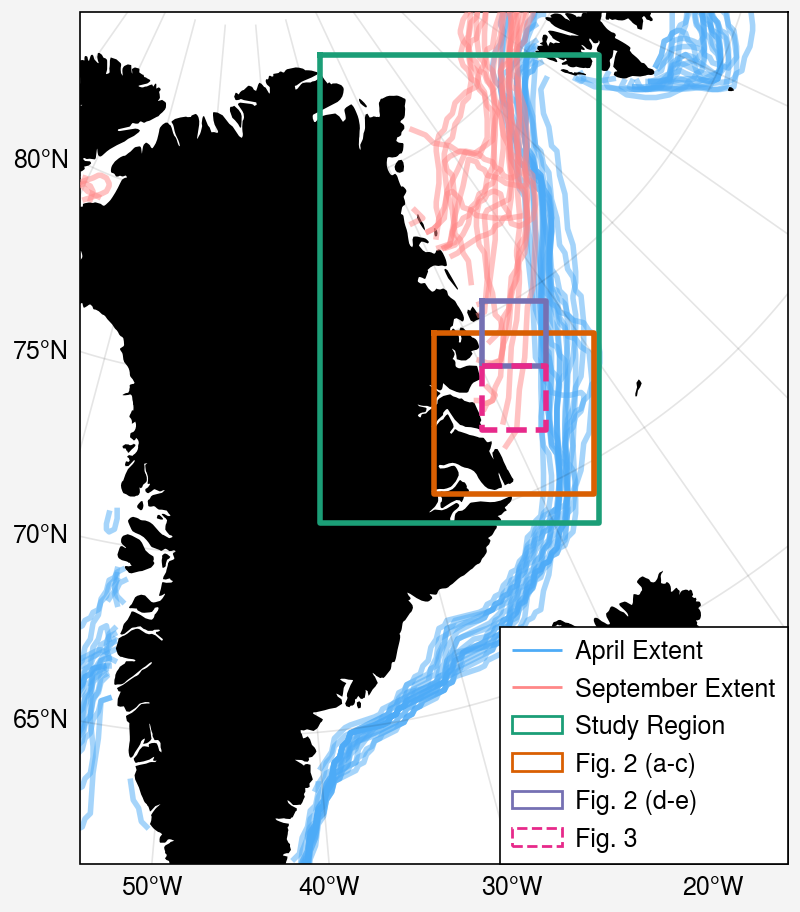

In [24]:
%run ../scripts/01_plot_study_region.py

In [26]:
x0 = 850
y0 = -1700
xlims = (0.75e6, 0.95e6)
ylims = (-1.8e6, -1.6e6)

(750, 950)

# Figure 2
Reviewer 1: "If I understand correctly, panels d and e are intended as zoomed-in views of panels a–c. However, based on their coordinates, they appear to extend beyond the spatial range of panels a–c. Please clarify this apparent inconsistency."
- That is inconsistent, and should be fixed. 

Reviewer 2: Missing units in Fig 2f.

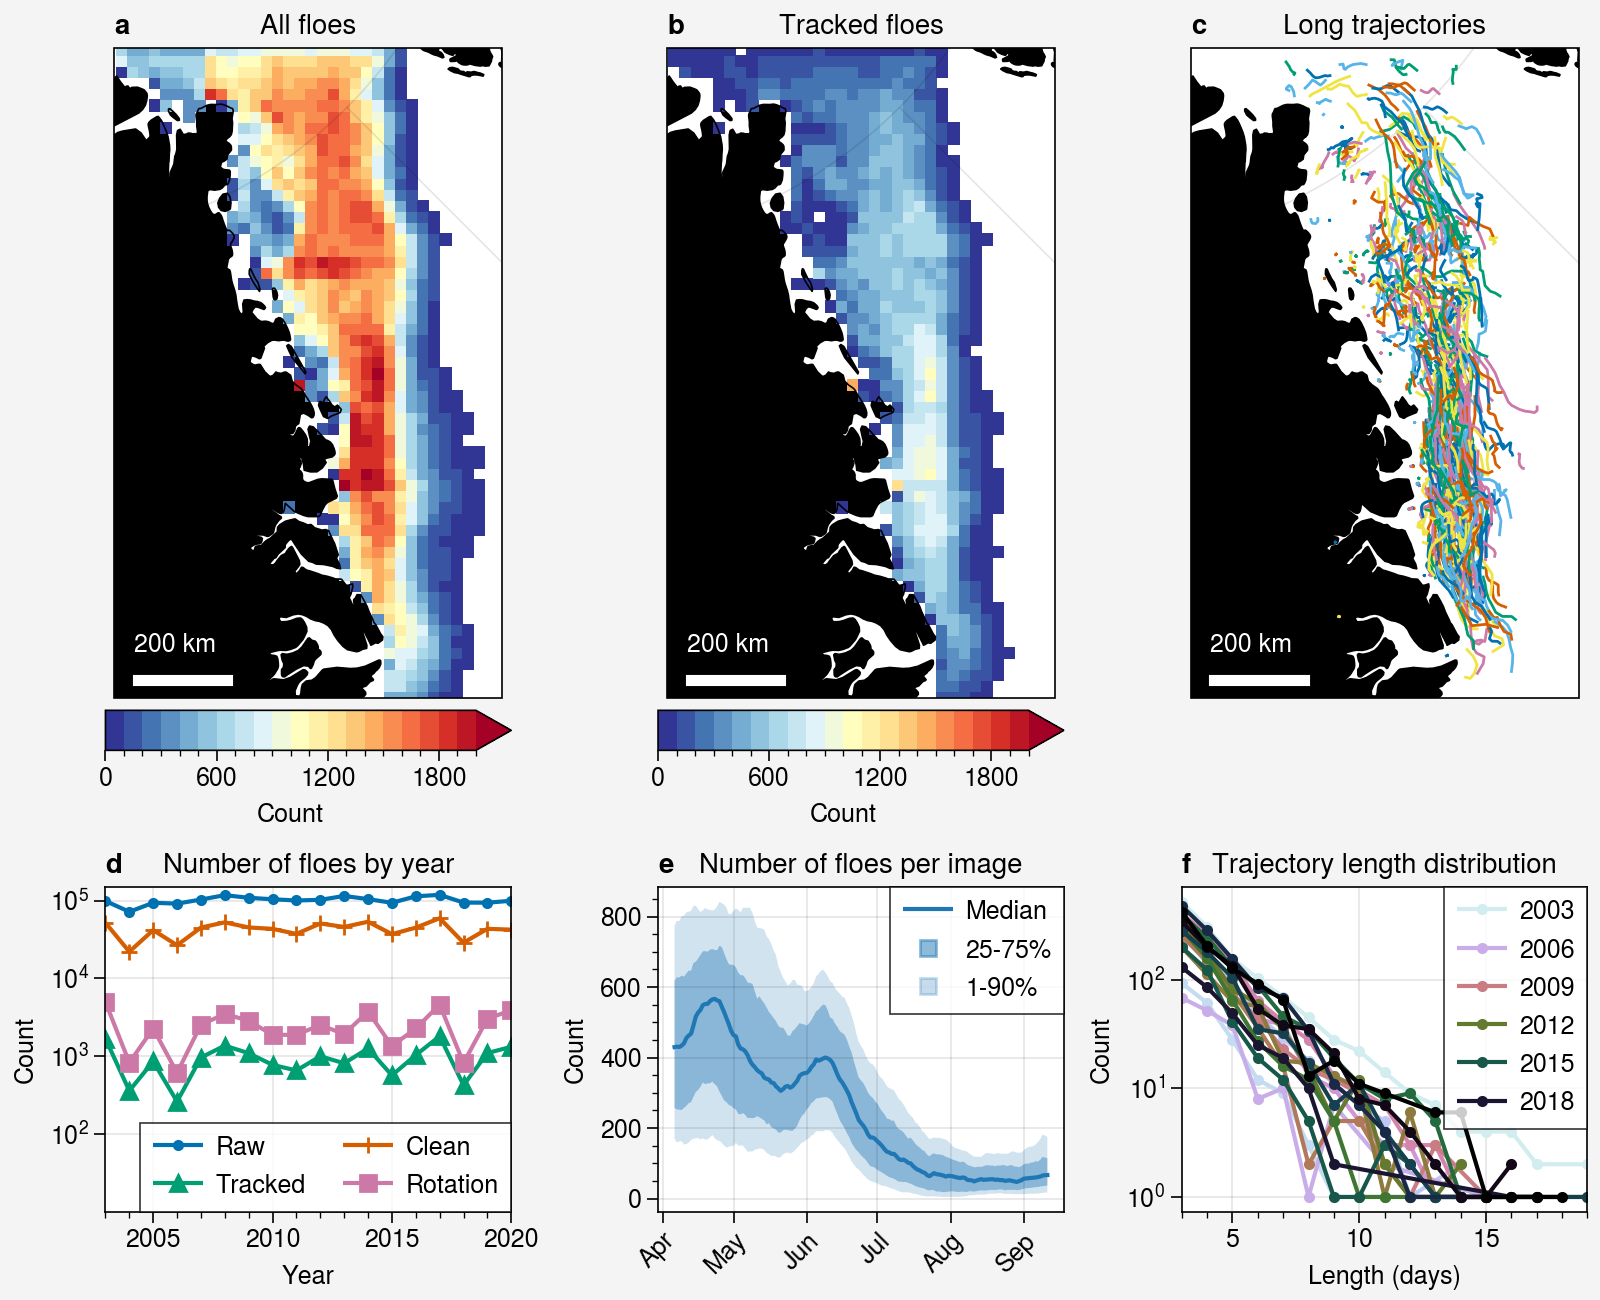

In [27]:
%run ../scripts/plot_fig_05_data_summary.py

# Additional figure for reviewer
"At present, the manuscript only provides the overall order of magnitude of the extracted and tracked floes, together with the distribution of trajectory lengths. It would be helpful if the authors could provide, in the supplementary material, the effective sample sizes by month and/or under different ice-concentration conditions. This would make it easier for readers to judge whether the trajectory-based results are statistically robust and representative."

In [2]:
data = []
for year in range(2003, 2021):
    for month in range(4, 10):
        idx = (floe_lib_raw.datetime.dt.year == year) & (floe_lib_raw.datetime.dt.month == month)
        tr_idx = (trajectories.datetime.dt.year == year) & (trajectories.datetime.dt.month == month)
        n = len(floe_lib_raw.loc[idx])
        amax = floe_lib_raw.loc[idx].area.max()
        amin = floe_lib_raw.loc[idx].area.min()
        n_passing = len(floe_lib_raw.loc[idx & floe_lib_raw.final_classification])        
        n_vel = len(trajectories.loc[tr_idx, 'u'].dropna())
        n_tracked = len(np.unique(trajectories.loc[tr_idx, 'floe_id'].dropna()))
        n_rotation = len(trajectories.loc[tr_idx, 'zeta'].dropna())
        data.append([year, month, amax, amin, n, n_passing, n_vel, n_tracked, n_rotation])
    
data_table = pd.DataFrame(data, columns=['year', 'month', 'max_pixels', 'min_pixels', 'n_init','n_passing', 'n_vel',  'n_tracked', 'n_rotation'])
# data_table.set_index('year', inplace=True)

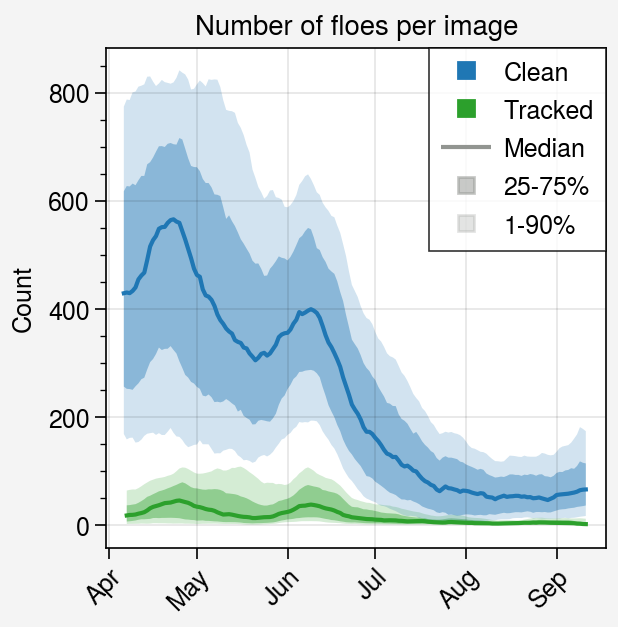

In [3]:
floe_lib_clean['doy'] = floe_lib_clean.datetime.dt.dayofyear
floe_lib_clean['year'] = floe_lib_clean.datetime.dt.year
count_range = floe_lib_clean.groupby(['year', 'doy']).count().pivot_table(index='year', columns='doy', values='datetime').quantile([0.1, 0.25, 0.5, 0.75, 0.9], axis=0)
smoothed_count_range = count_range.T.rolling(15, center=True).mean()


trajectories['doy'] = trajectories.datetime.dt.dayofyear
trajectories['year'] = trajectories.datetime.dt.year
count_range = trajectories.groupby(['year', 'doy']).count().pivot_table(index='year', columns='doy', values='datetime').quantile([0.1, 0.25, 0.5, 0.75, 0.9], axis=0)
trajectory_smoothed_count_range = count_range.T.rolling(15, center=True).mean()
fig, ax = pplt.subplots()
ax.plot(trajectory_smoothed_count_range[0.5],
        shadedata=[trajectory_smoothed_count_range[0.25],
                   trajectory_smoothed_count_range[0.75]],
       fadedata=[trajectory_smoothed_count_range[0.1],
                 trajectory_smoothed_count_range[0.9]], color='tab:green')

ax.plot(smoothed_count_range[0.5],
        shadedata=[smoothed_count_range[0.25],
                   smoothed_count_range[0.75]],
       fadedata=[smoothed_count_range[0.1],
                 smoothed_count_range[0.9]], color='tab:blue')

dr = pd.date_range('2020-04-01', '2020-09-01', freq='1MS')
ax.format(xlocator=dr.dayofyear, xformatter=[d.strftime('%b') for d in dr], xrotation=45)
h = []
l = []
for alpha, ls, m, c, label in zip(
    [1, 1, 1,  0.5, 0.25],
    ['', '', '-', '', ''],
    ['s', 's', '', 's', 's'],
    ['tab:blue', 'tab:green', 'gray', 'gray', 'gray'],
    ['Clean', 'Tracked', 'Median', '25-75%', '1-90%']):
    h.append(ax.plot([],[],color=c, alpha=alpha, ls=ls, m=m))
    l.append(label)
ax.legend(h, l, ncols=1, loc='ur')
ax.format(ylabel='Count', xlabel='', title='Number of floes per image')


In [31]:
trajectories.columns

Index(['datetime', 'floe_id', 'longitude', 'latitude', 'x_stere', 'y_stere',
       'area', 'perimeter', 'axis_major_length', 'axis_minor_length',
       'solidity', 'circularity', 'nsidc_sic', 'lr_probability', 'zeta',
       'zeta_est', 'u', 'v', 'bearing', 'speed', 'area_km2', 'perimeter_km',
       'axis_major_length_km', 'axis_minor_length_km', 'edge_dist_km',
       'coast_dist_km', 'u_nsidc', 'v_nsidc', 'u5D_nsidc', 'v5D_nsidc',
       'u15D_nsidc', 'v15D_nsidc', 'u31D_nsidc', 'v31D_nsidc', 'doy', 'year'],
      dtype='object')

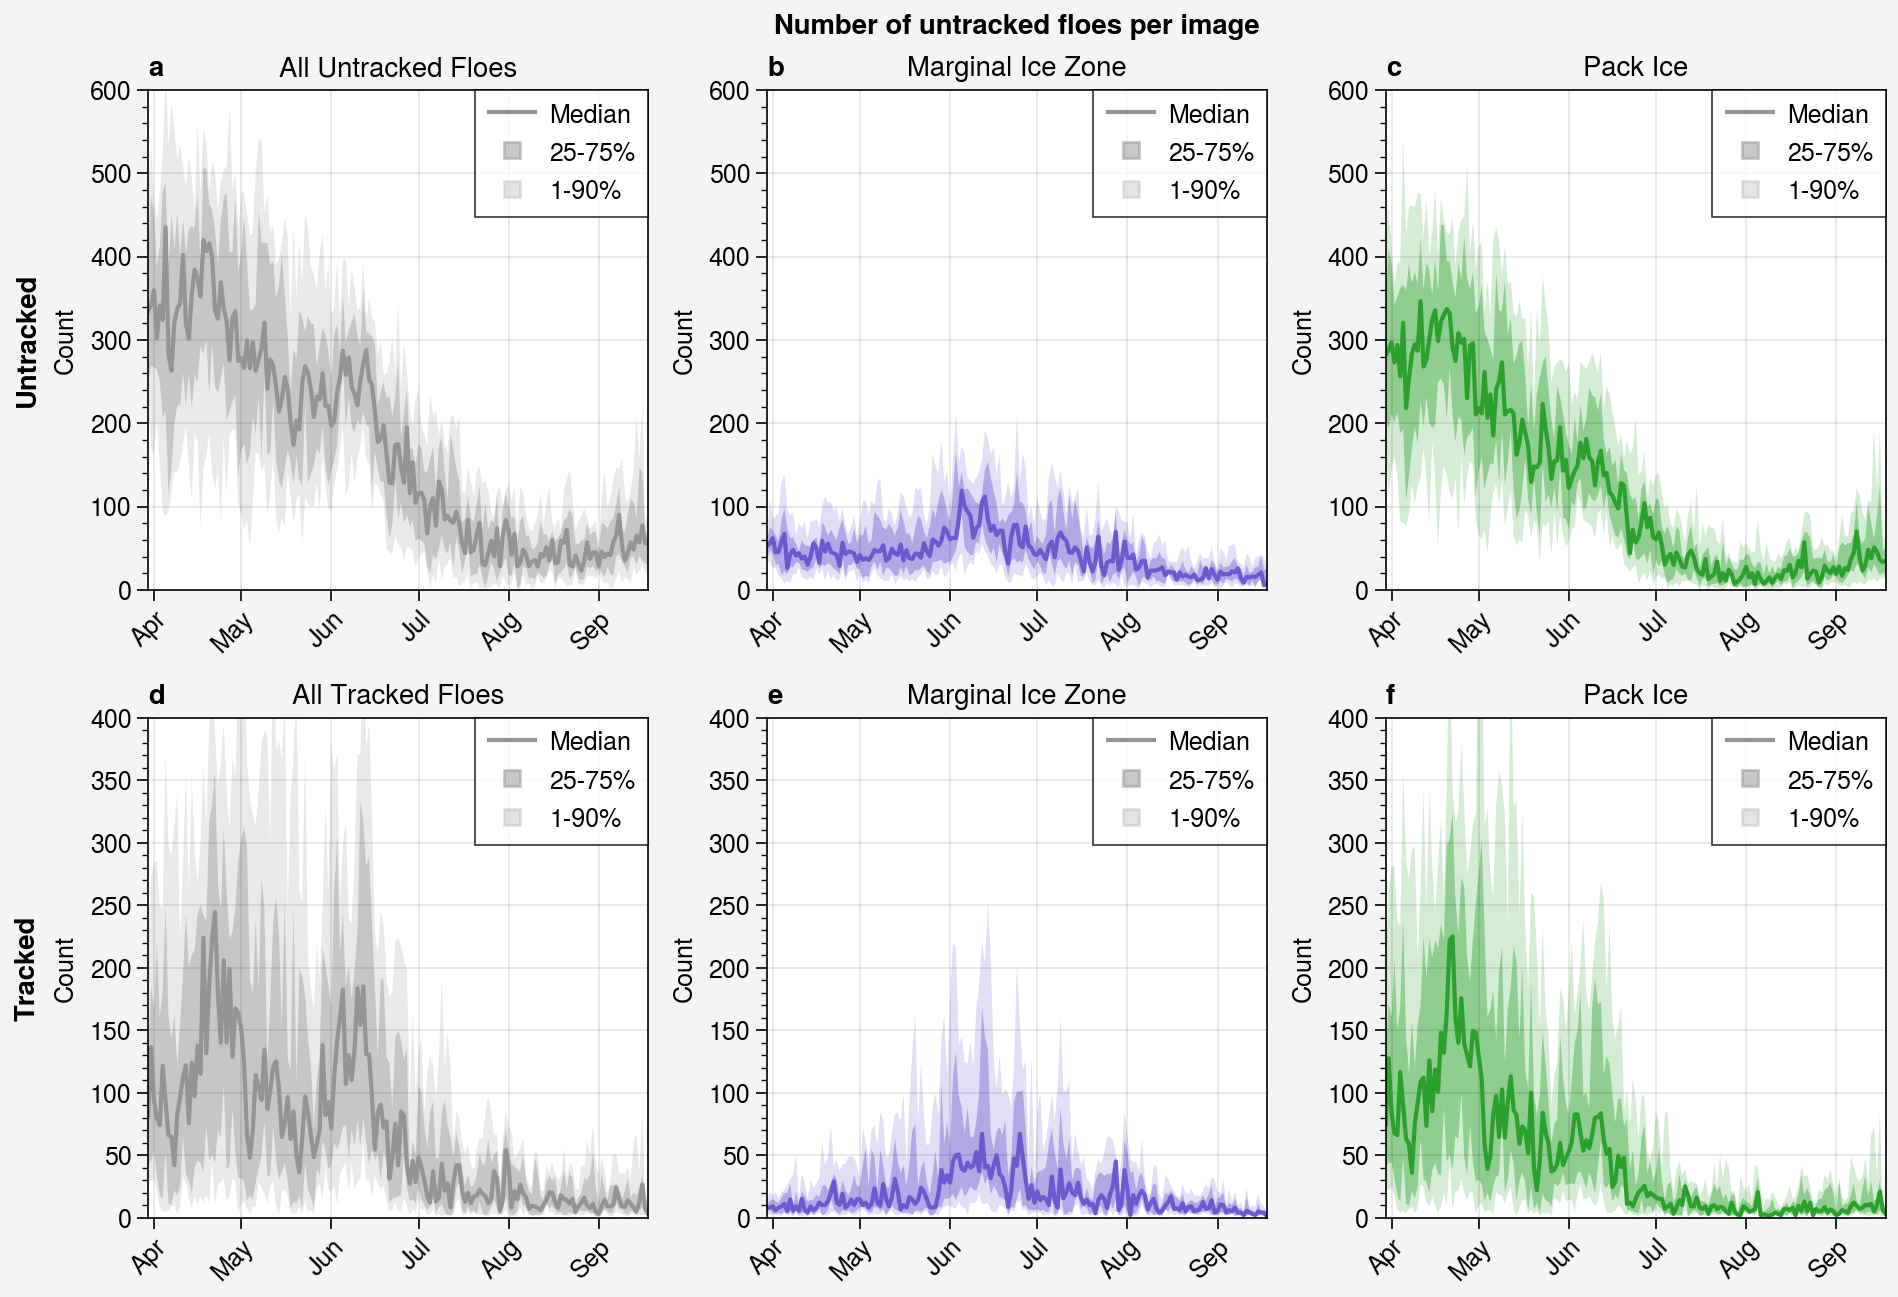

In [20]:
fig, axs = pplt.subplots(ncols=3, nrows=2, sharey=False, sharex=False)

df_ = floe_lib_clean.copy()
df_['doy'] = df_.datetime.dt.dayofyear
df_['year'] = df_.datetime.dt.year
unmatched = df_.floe_id == "unmatched"
# MIZ vs pack ice
miz_idx = df_.nsidc_sic.between(0.15, 0.85) & unmatched
pack_idx = (df_.nsidc_sic > 0.85) & unmatched

for ax, color, idx in zip(axs[0,:], ['gray', 'slateblue', 'tab:green'], [unmatched, miz_idx, pack_idx]):
    count_range = df_.loc[idx].groupby(['year', 'doy']).count().pivot_table(
        index='year', columns='doy', values='datetime').quantile([0.1, 0.25, 0.5, 0.75, 0.9], axis=0).T
    ax.plot(count_range[0.5],
            shadedata=[count_range[0.25],
                       count_range[0.75]],
           fadedata=[count_range[0.1],
                     count_range[0.9]], color=color)

dr = pd.date_range('2020-04-01', '2020-09-01', freq='1MS')
axs.format(xlocator=dr.dayofyear, xformatter=[d.strftime('%b') for d in dr], xrotation=45)
h = []
l = []
for alpha, ls, m, c, label in zip(
    [1,  0.5, 0.25],
    ['-', '', ''],
    ['', 's', 's'],
    ['gray', 'gray', 'gray'],
    ['Median', '25-75%', '1-90%']):
    h.append(ax.plot([],[],color=c, alpha=alpha, ls=ls, m=m))
    l.append(label)
axs.legend(h, l, ncols=1, loc='ur')
axs.format(ylabel='Count', xlabel='', suptitle='Number of untracked floes per image', abc=True)
axs[0,0].format(title='All Untracked Floes')
axs[0,1].format(title='Marginal Ice Zone')
axs[0,2].format(title='Pack Ice')



df_ = floe_lib_clean.copy()
df_['doy'] = df_.datetime.dt.dayofyear
df_['year'] = df_.datetime.dt.year
matched = df_.floe_id != "unmatched"
# MIZ vs pack ice
miz_idx = df_.nsidc_sic.between(0.15, 0.85) & matched
pack_idx = (df_.nsidc_sic > 0.85) & matched

for ax, color, idx in zip(axs[1,:], ['gray', 'slateblue', 'tab:green'], [matched, miz_idx, pack_idx]):
    count_range = df_.loc[idx].groupby(['year', 'doy']).count().pivot_table(
        index='year', columns='doy', values='datetime').quantile([0.1, 0.25, 0.5, 0.75, 0.9], axis=0).T
    ax.plot(count_range[0.5],
            shadedata=[count_range[0.25],
                       count_range[0.75]],
           fadedata=[count_range[0.1],
                     count_range[0.9]], color=color)

dr = pd.date_range('2020-04-01', '2020-09-01', freq='1MS')
axs.format(xlocator=dr.dayofyear, xformatter=[d.strftime('%b') for d in dr], xrotation=45)
h = []
l = []
for alpha, ls, m, c, label in zip(
    [1,  0.5, 0.25],
    ['-', '', ''],
    ['', 's', 's'],
    ['gray', 'gray', 'gray'],
    ['Median', '25-75%', '1-90%']):
    h.append(ax.plot([],[],color=c, alpha=alpha, ls=ls, m=m))
    l.append(label)
axs.legend(h, l, ncols=1, loc='ur')
axs.format(ylabel='Count', xlabel='', leftlabels=['Untracked', 'Tracked'], abc=True)
axs[1,0].format(title='All Tracked Floes')
axs[1,1].format(title='Marginal Ice Zone')
axs[1,2].format(title='Pack Ice')

axs[0, :].format(ylim=(0, 600))
axs[1, :].format(ylim=(0, 400))
fig.save('../figures/figS1_floe_count_time_series.png', dpi=300)

In [11]:
count_range

doy,90,91,92,93,94,95,96,97,98,99,...,253,254,255,256,257,258,259,260,261,262
0.10,218.30,169.2,162.80,204.2,150.4,93.8,88.00,94.2,116.0,140.8,...,8.6,15.4,12.8,8.90,28.30,18.3,23.8,29.4,21.60,18.50
0.25,249.50,269.0,266.75,265.0,250.0,206.0,215.25,114.0,144.0,199.0,...,33.5,28.0,20.5,39.25,40.00,30.0,41.0,35.0,32.00,29.00
0.50,334.50,342.0,359.50,302.0,341.5,324.0,435.00,282.0,263.0,321.0,...,53.0,35.0,44.0,57.00,48.50,65.5,57.0,77.0,56.00,55.00
0.75,411.25,472.0,453.25,388.0,411.5,478.0,489.25,385.0,450.0,410.0,...,69.5,70.0,91.5,108.75,105.75,85.5,146.0,141.0,68.75,68.75
0.90,481.30,532.4,472.20,444.8,475.1,525.4,616.00,532.2,583.0,555.6,...,158.0,115.6,105.2,119.80,146.70,205.8,157.6,226.6,82.30,92.80


In [ ]:
trajectories['doy'] = trajectories.datetime.dt.dayofyear
trajectories['year'] = trajectories.datetime.dt.year

# MIZ vs pack ice
miz_idx = trajectories.nsidc_sic.between(0.15, 0.85)
pack_idx = trajectories.nsidc_sic > 0.85

count_range = trajectories.groupby(['year', 'doy']).count().pivot_table(index='year', columns='doy', values='datetime').quantile([0.1, 0.25, 0.5, 0.75, 0.9], axis=0)
trajectory_smoothed_count_range = count_range.T.rolling(1, center=True).mean()
fig, ax = pplt.subplots(ncols=3, sharey=True, sharex=False)
ax[0].plot(trajectory_smoothed_count_range[0.5],
        shadedata=[trajectory_smoothed_count_range[0.25],
                   trajectory_smoothed_count_range[0.75]],
       fadedata=[trajectory_smoothed_count_range[0.1],
                 trajectory_smoothed_count_range[0.9]], color='gray')

count_range = trajectories.loc[miz_idx].groupby(['year', 'doy']).count().pivot_table(index='year', columns='doy', values='datetime').quantile([0.1, 0.25, 0.5, 0.75, 0.9], axis=0)
trajectory_smoothed_count_range = count_range.T.rolling(1, center=True).mean()

ax[1].plot(trajectory_smoothed_count_range[0.5],
        shadedata=[trajectory_smoothed_count_range[0.25],
                   trajectory_smoothed_count_range[0.75]],
       fadedata=[trajectory_smoothed_count_range[0.1],
                 trajectory_smoothed_count_range[0.9]], color='slateblue')

count_range = trajectories.loc[pack_idx].groupby(['year', 'doy']).count().pivot_table(index='year', columns='doy', values='datetime').quantile([0.1, 0.25, 0.5, 0.75, 0.9], axis=0)
trajectory_smoothed_count_range = count_range.T.rolling(1, center=True).mean()

ax[2].plot(trajectory_smoothed_count_range[0.5],
        shadedata=[trajectory_smoothed_count_range[0.25],
                   trajectory_smoothed_count_range[0.75]],
       fadedata=[trajectory_smoothed_count_range[0.1],
                 trajectory_smoothed_count_range[0.9]], color='tab:green')


dr = pd.date_range('2020-04-01', '2020-09-01', freq='1MS')
ax.format(xlocator=dr.dayofyear, xformatter=[d.strftime('%b') for d in dr], xrotation=45)
h = []
l = []
for alpha, ls, m, c, label in zip(
    [1,  0.5, 0.25],
    ['-', '', ''],
    ['', 's', 's'],
    ['gray', 'gray', 'gray'],
    ['Median', '25-75%', '1-90%']):
    h.append(ax.plot([],[],color=c, alpha=alpha, ls=ls, m=m))
    l.append(label)
ax.legend(h, l, ncols=1, loc='ur')
ax.format(ylabel='Count', xlabel='', suptitle='Number of tracked floes per image', abc=True)
ax[0].format(title='All Tracked Floes')
ax[1].format(title='Marginal Ice Zone')
ax[2].format(title='Pack Ice')
fig.save('../figures/figS1_tracked_floes_time_series.png', dpi=300)

## Judging whether the trajectory-based data are robust
* The number of tracked floes follows a similar pattern as in Fig 5e, with a smaller range (median 20-50 tracked floes per image for Apr-Jul).
* It is clear that we are tracking waaayyy fewer floes than we analyze for the FSD, so there's potential for strong improvement
* Figure 14g-i already provides a 2-d histogram of the number of drift vectors available for April, May and June, respectively.
* 

Month 4 mean difference 0.09
Month 5 mean difference 0.09
Month 6 mean difference 0.11
31D U_along 7.995 cm/s
Fitted exponential dist. scale param: 0.74
31D U_fluctuating 6.341 cm/s
Fitted exponential dist. scale param: 0.75


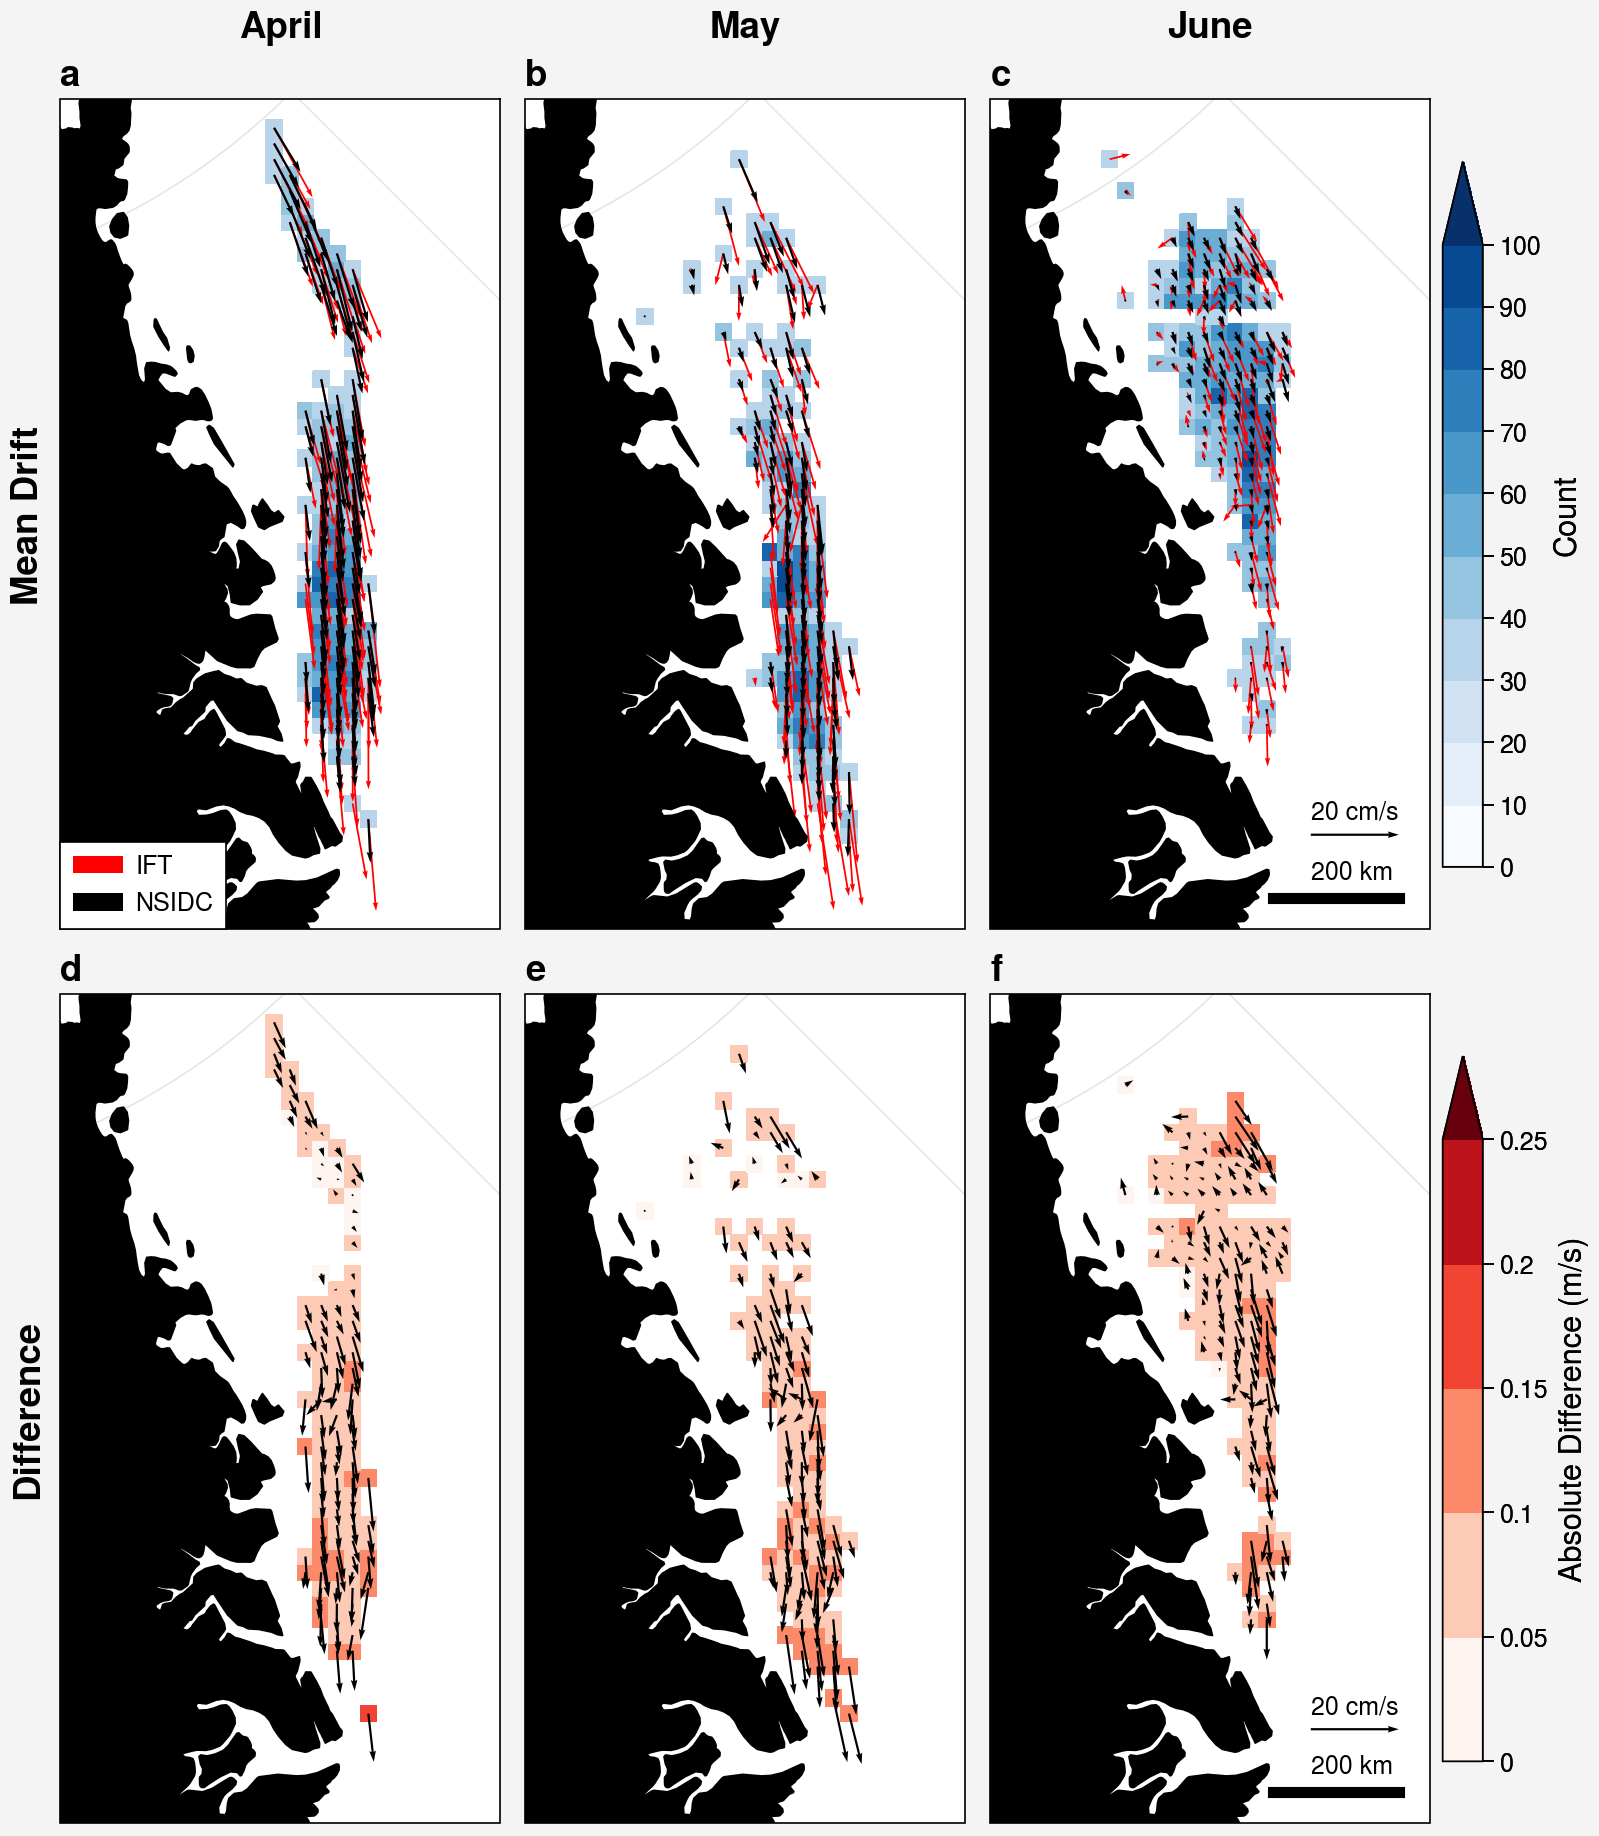

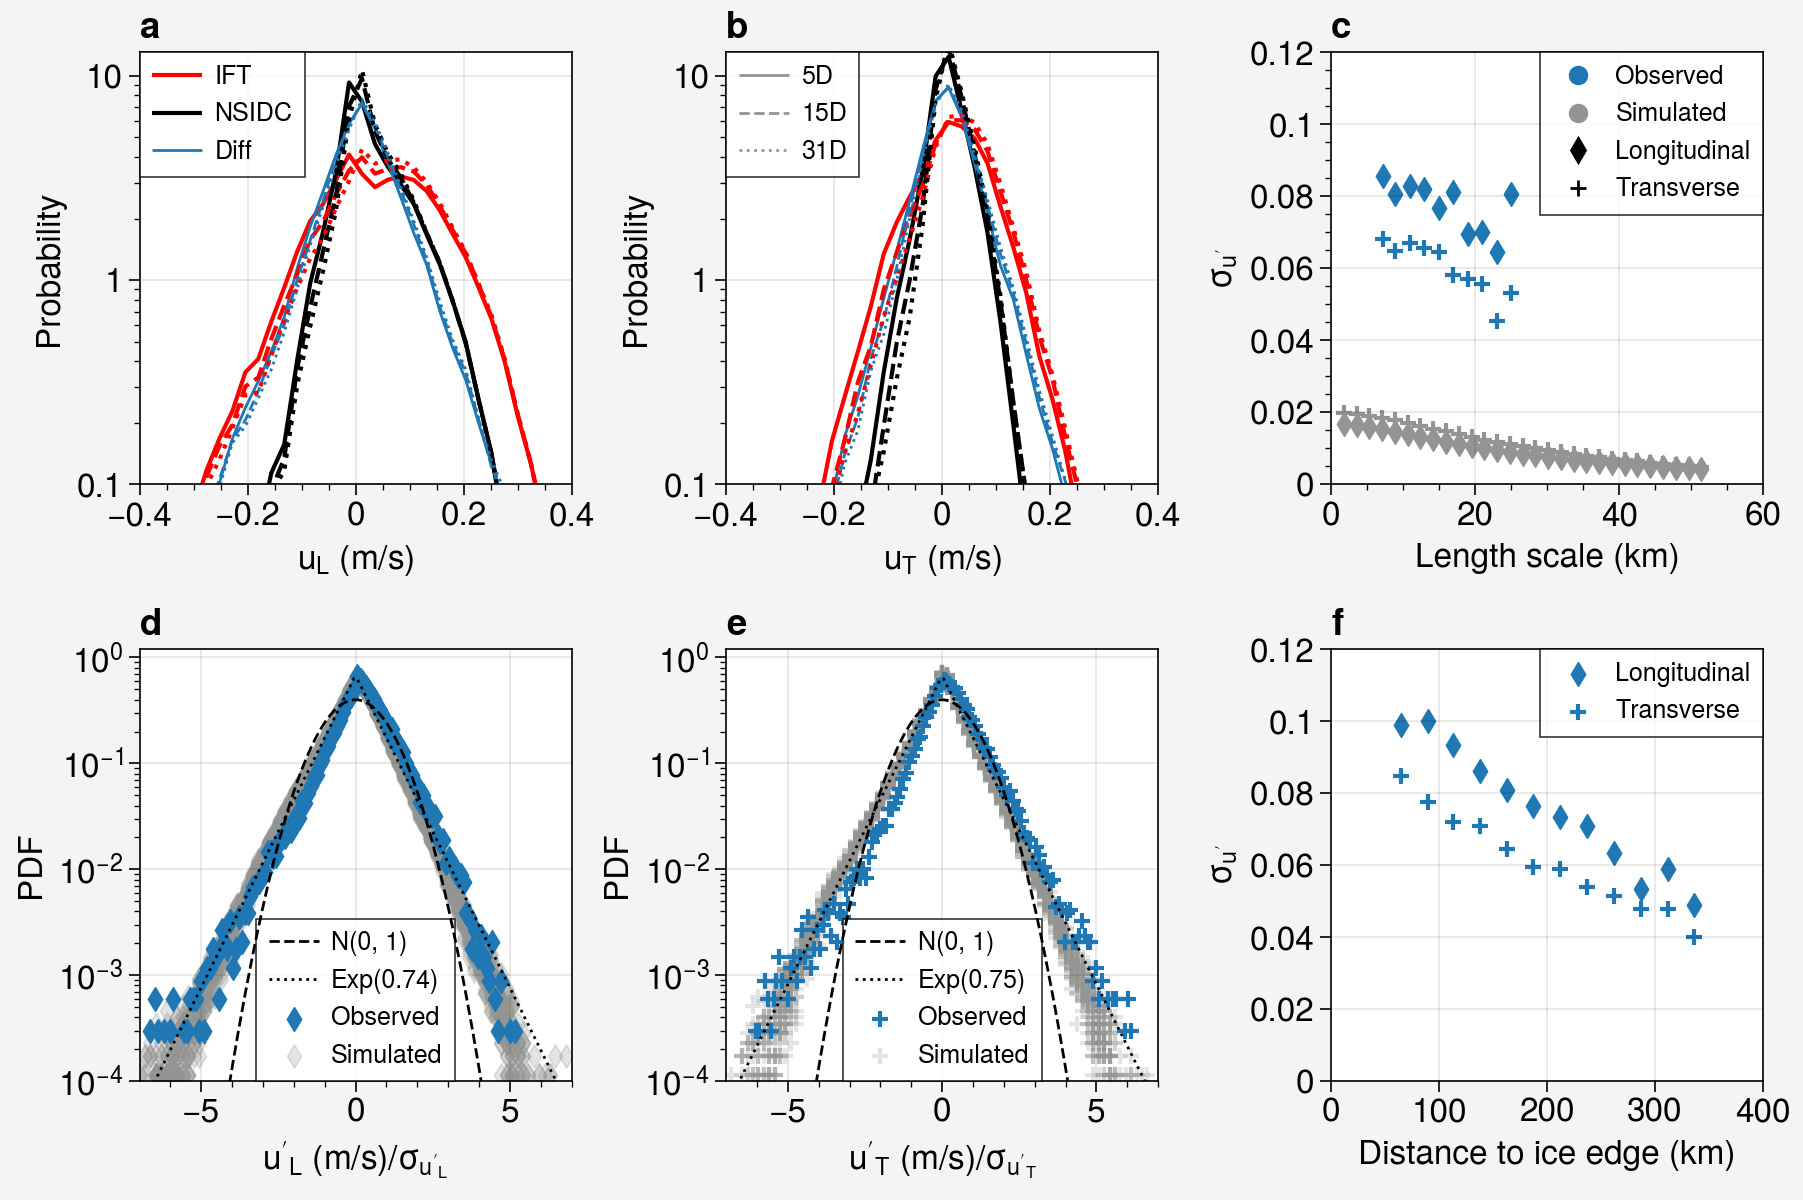

In [17]:
%run ../scripts/07_velocity_figures.py

In [58]:
pass_times = pd.DataFrame([
['2014-04-27 12:39:06',   'aqua'],
['2014-04-27 13:55:48',   'terra'],
['2014-04-28 11:44:06',	'aqua'],
['2014-04-28 14:38:44',	'terra'],
['2014-04-29 12:26:54',	'aqua'],
['2014-04-29 13:43:46',	'terra'],
['2014-04-30 13:09:48',	'aqua'],
['2014-04-30 14:26:34',	'terra']], columns=['datetime', 'satellite'])
pass_times['datetime'] = pd.to_datetime(pass_times['datetime'].values)
pass_times.sort_values('datetime', inplace=True)

data_loc = '../data/example_images_extended/'

# load images
tc_images = {}
floe_images_clean = {}
floe_images_raw = {}

for date, satellite in zip(pass_times['datetime'], pass_times['satellite']):
    tc_images[date] = rio.open('../data/example_images_extended//{d}.{s}.truecolor.250m.tiff'.format(d=date.strftime('%Y%m%d'), s=satellite))
    floe_images_raw[date] = rio.open('../data/example_images_extended/{d}.{s}.labeled_raw.250m.tiff'.format(d=date.strftime('%Y%m%d'), s=satellite))
    floe_images_clean[date] = rio.open('../data/example_images_extended/{d}.{s}.labeled_clean.250m.tiff'.format(d=date.strftime('%Y%m%d'), s=satellite))

TODO: Datetime alignment
- The dates in the tracked floe CSV file don't perfectly match the dates in the SOIT file.

NameError: name 'Images' is not defined

In [60]:
floe = '2014_01741'
comp_floe_loc = plot_floes.loc[plot_floes.floe_id == floe, ['x_stere', 'y_stere']].mean()
dx = 1e5
dy = 1e5
nearby_floes = plot_floes.loc[np.sqrt((plot_floes.x_stere - comp_floe_loc.x_stere)**2 + \
                                      (plot_floes.y_stere - comp_floe_loc.y_stere)**2) < dx]
nearby_floes = nearby_floes.groupby('floe_id').filter(lambda x: np.sum([d in x.datetime.values for d in plot_dates])>2)
floes = np.unique(nearby_floes.floe_id)

In [61]:
imdate = pd.to_datetime('2014-04-27 12:39:06')
left, bottom, right, top = tc_images[imdate].bounds
left /= 1e3
bottom /= 1e3
right /= 1e3
top /= 1e3

x0 = 850
y0 = -1700
left -= x0
right -= x0
top -= y0
bottom -= y0

floe = '2014_01741'
comp_floe_loc = plot_floes.loc[plot_floes.floe_id == floe, ['x_stere', 'y_stere']].mean()
dx = 1e5
dy = 1e5
nearby_floes = plot_floes.loc[np.sqrt((plot_floes.x_stere - comp_floe_loc.x_stere)**2 + \
                                      (plot_floes.y_stere - comp_floe_loc.y_stere)**2) < dx]
nearby_floes = nearby_floes.groupby('floe_id').filter(lambda x: np.sum([d in x.datetime.values for d in plot_dates])>2)
floes = np.unique(nearby_floes.floe_id)
colors = [c['color'] for c in pplt.Cycle('Dark2', len(floes))]
colors = {f_id: c for f_id, c in zip(floes, colors)}
    
for idx in np.arange(0, 8, 2):
    fig, ax = pplt.subplots(width=6, spanx=False, spany=False)
    

    date_aqua = pass_times.loc[idx, 'datetime']
    date_terra = pass_times.loc[idx + 1, 'datetime'] 
    
    ax.imshow(reshape_as_image(tc_images[date_aqua].read()), extent=[left, right, bottom, top])
    for date, color in zip([date_aqua, date_terra], ['r', 'b']):
        image = floe_images_clean[date].read().squeeze()
        outlines = image - skimage.morphology.erosion(image, skimage.morphology.disk(2))
        ax.pcolorfast(np.linspace(left, right, outlines.shape[1]),
              np.linspace(top, bottom, outlines.shape[0]),
              np.ma.masked_array(outlines, mask=outlines == 0), color=color)
    plot_df = plot_floes.loc[(plot_floes.datetime.dt.date == date_aqua.date()) & (plot_floes.satellite == 'aqua')]
    ax.scatter(plot_df.x_stere/1e3 - x0, plot_df.y_stere/1e3 - y0, color='r', marker='s', ms=4)

    plot_df = plot_floes.loc[(plot_floes.datetime.dt.date == date_terra.date()) & (plot_floes.satellite == 'terra')]
    ax.scatter(plot_df.x_stere/1e3 - x0, plot_df.y_stere/1e3 - y0, color='b', marker='.', ms=4)

    for floe in colors:
        c = colors[floe]
        df_floe = plot_floes.loc[plot_floes.floe_id == floe].set_index('datetime')

        # Plot the main tracked floe
        for floe_date in df_floe.index:
            if floe_date <= date:
                ax.pcolorfast(np.linspace(left, right, outlines.shape[1]),
                      np.linspace(top, bottom, outlines.shape[0]),
                      np.ma.masked_array(outlines, mask=outlines != df_floe.loc[floe_date, 'label']), color=c, zorder=10)
        
                ax.plot(df_floe.loc[df_floe.index <= date, 'x_stere'].values/1e3 - x0,
                        df_floe.loc[df_floe.index <= date, 'y_stere'].values/1e3 - y0, color=c, marker='.', facecolor='w')
                ax.plot(df_floe.loc[floe_date, 'x_stere']/1e3 - x0,
                        df_floe.loc[floe_date, 'y_stere']/1e3 - y0, color=c, marker='.')    

    ax.format(title=date.strftime('%Y-%m-%d (raw shapes)'), yreverse=False, ylim=(-100, 100), xlim=(-100, 100),)
    fig.save('../figures/test_fig3_tracking_clean_' + date.strftime('%Y%m%d') + '.png', dpi=300)
    pplt.close(fig)

In [73]:
plot_floes.sort_values('area')[::-1].groupby('floe_id').filter(lambda x: len(x) > 4)

,level_0,level_1,datetime,satellite,floe_id,label,longitude,latitude,x_stere,y_stere,...,tc_channel2,fc_channel0,fc_channel1,fc_channel2,init_classification,lr_probability,lr_classification,final_classification,doy,year
420580,2014,20144,2014-04-24 12:08:04,aqua,2014_01310,146,-3.4834,79.2892,771227.3,-871203.7,...,233.5,17.8,239.3,241.4,TP,0.964,True,True,114,2014
420881,2014,20642,2014-04-24 13:25:02,terra,2014_01310,159,-3.5723,79.2690,771335.6,-874055.0,...,234.1,12.4,239.5,240.9,TP,0.970,True,True,114,2014
418753,2014,17918,2014-04-22 12:20:22,aqua,2014_01310,113,-2.8402,79.5964,758436.9,-837618.9,...,231.7,1.5,236.3,238.7,TP,0.958,True,True,112,2014
419186,2014,18424,2014-04-22 13:37:19,terra,2014_01310,136,-2.8442,79.5702,760301.1,-839794.9,...,231.4,0.6,236.8,239.0,TP,0.991,True,True,112,2014
422362,2014,22953,2014-04-27 12:38:45,aqua,2014_01310,161,-5.0733,78.6622,790742.2,-944821.0,...,231.9,25.4,238.7,240.2,TP,0.977,True,True,117,2014
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
425616,2014,27988,2014-05-02 11:19:18,aqua,2014_02075,240,-20.4077,70.1797,902182.6,-1971239.8,...,233.5,36.1,239.4,243.7,TP,0.997,True,True,122,2014
423730,2014,25078,2014-04-29 12:26:32,aqua,2014_01985,348,-18.6450,72.7406,836083.7,-1687606.7,...,234.5,2.7,240.4,241.2,TP,1.000,True,True,119,2014
423250,2014,24182,2014-04-28 11:43:40,aqua,2014_01985,210,-18.3657,72.8875,837008.3,-1668972.3,...,233.1,2.2,239.8,242.5,TP,1.000,True,True,118,2014
424057,2014,25592,2014-04-29 13:43:33,terra,2014_01983,230,-18.8358,73.1300,811458.2,-1651703.4,...,229.6,4.2,236.4,239.2,TP,0.999,True,True,119,2014


In [74]:
plot_floes.loc[plot_floes.floe_id == '2014_01310', ['floe_id', 'label', 'datetime', 'area']]

,floe_id,label,datetime,area
418753,2014_01310,113,2014-04-22 12:20:22,27261.0
419186,2014_01310,136,2014-04-22 13:37:19,27197.0
420580,2014_01310,146,2014-04-24 12:08:04,27883.0
420881,2014_01310,159,2014-04-24 13:25:02,27687.0
421584,2014_01310,189,2014-04-26 11:55:52,26971.0
421923,2014_01310,210,2014-04-26 13:12:44,25756.0
422362,2014_01310,161,2014-04-27 12:38:45,27176.0


In [47]:
date.round('1h')

Timestamp('2014-04-30 14:00:00')

In [24]:
imdate = pd.to_datetime('2014-04-27 12:38:45')
plot_floes = floe_lib_clean.loc[(floe_lib_clean.floe_id != 'unmatched') &
    (floe_lib_clean.datetime.dt.year == imdate.year)].groupby('floe_id').filter(lambda x: np.any((x.datetime > '2014-04-27') & (x.datetime <= '2014-04-30')))


In [34]:
colors = [c['color'] for c in pplt.Cycle('Dark2', 12)]


,level_0,level_1,datetime,satellite,floe_id,label,longitude,latitude,x_stere,y_stere,...,tc_channel2,fc_channel0,fc_channel1,fc_channel2,init_classification,lr_probability,lr_classification,final_classification,doy,year
424395,2014,26048,2014-04-30 11:31:29,aqua,2014_02089,320,-8.1892,77.0252,845624.1,-1129924.7,...,228.1,165.5,232.1,236.5,TP,0.492,False,True,120,2014
424396,2014,26049,2014-04-30 11:31:29,aqua,2014_02090,387,6.9735,79.8068,872019.8,-681946.9,...,220.4,155.2,228.6,230.8,TP,0.348,False,True,120,2014
424397,2014,26050,2014-04-30 11:31:29,aqua,2014_02091,155,-5.9409,78.6162,779516.7,-960594.6,...,227.5,169.3,231.4,235.0,TP,0.548,True,True,120,2014
424398,2014,26051,2014-04-30 11:31:29,aqua,2014_02093,136,-7.4897,78.3890,768400.3,-1001027.1,...,226.1,168.6,230.0,234.1,TP,0.400,False,True,120,2014
424399,2014,26052,2014-04-30 11:31:29,aqua,2014_02094,532,-18.9904,69.9805,960407.2,-1968285.3,...,232.1,1.0,236.7,242.8,TP,0.999,True,True,120,2014
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
424489,2014,26167,2014-04-30 11:31:29,aqua,2014_02014,330,-13.8093,74.8278,855992.0,-1413930.9,...,227.3,5.0,237.3,239.5,TP,0.978,True,True,120,2014
424490,2014,26168,2014-04-30 11:31:29,aqua,2014_02017,153,-18.7057,73.8827,778357.2,-1575277.8,...,228.8,2.1,235.2,239.8,TP,0.996,True,True,120,2014
424491,2014,26169,2014-04-30 11:31:29,aqua,2014_02018,254,-2.0586,78.8658,824176.3,-885635.4,...,225.7,161.6,231.3,234.4,TP,0.273,False,True,120,2014
424492,2014,26170,2014-04-30 11:31:29,aqua,2014_02005,412,-20.5544,70.4344,885387.8,-1947703.1,...,235.1,0.8,240.0,242.5,TP,0.997,True,True,120,2014


In [ ]:
# Dates with multiple tracked floes, all from the Aqua satellite
plot_dates = [pd.to_datetime(x) for x in ['2014-04-27 12:38:45', '2014-04-28 11:43:40',
                                          '2014-04-29 12:26:32', '2014-04-30 11:31:29']]

# load images
tc_images = {}
floe_images = {}

for date in plot_dates:
    tc_images[date] = rio.open('../data/example_images/{d}.aqua.truecolor.250m.tiff'.format(d=date.strftime('%Y%m%d')))
    floe_images[date] = rio.open('../data/example_images/{d}.aqua.labeled_clean.250m.tiff'.format(d=date.strftime('%Y%m%d')))

imdate = pd.to_datetime('2014-04-27 12:38:45')
plot_floes = floe_lib_clean.loc[(floe_lib_clean.floe_id != 'unmatched') & (floe_lib_clean.datetime.dt.year == imdate.year)].groupby('floe_id').filter(lambda x: imdate in x.datetime.values)

# get nearby floes that have enough dates
floe = '2014_01741'
comp_floe_loc = plot_floes.loc[plot_floes.floe_id == floe, ['x_stere', 'y_stere']].mean()
dx = 1e5
dy = 1e5
nearby_floes = plot_floes.loc[np.sqrt((plot_floes.x_stere - comp_floe_loc.x_stere)**2 + \
                                      (plot_floes.y_stere - comp_floe_loc.y_stere)**2) < dx]
nearby_floes = nearby_floes.groupby('floe_id').filter(lambda x: np.sum([d in x.datetime.values for d in plot_dates])>2)
floes = np.unique(nearby_floes.floe_id)

left, bottom, right, top = tc_images[imdate].bounds
left /= 1e3
bottom /= 1e3
right /= 1e3
top /= 1e3

x0 = 850
y0 = -1700
left -= x0
right -= x0
top -= y0
bottom -= y0

fig, axs = pplt.subplots(ncols=2, nrows=2, width=6, spanx=False, spany=False)

colors = [c['color'] for c in pplt.Cycle('Dark2', 12)]

for ax, date in zip(axs,plot_dates):
    ax.imshow(reshape_as_image(tc_images[date].read()), extent=[left, right, bottom, top])
    image = floe_images[date].read().squeeze()
    
    outlines = image - skimage.morphology.erosion(image, skimage.morphology.disk(4))

    for c, floe in zip(colors, floes):
        df_floe = plot_floes.loc[plot_floes.floe_id == floe].set_index('datetime')

        # Plot the main tracked floe
        if date in df_floe.index:
            ax.pcolorfast(np.linspace(left, right, outlines.shape[1]),
                  np.linspace(top, bottom, outlines.shape[0]),
                  np.ma.masked_array(outlines, mask=outlines != df_floe.loc[date, 'label']), color=c)

            ax.plot(df_floe.loc[df_floe.index <= date, 'x_stere'].values/1e3 - x0,
                    df_floe.loc[df_floe.index <= date, 'y_stere'].values/1e3 - y0, color=c, marker='.', facecolor='w')
            ax.plot(df_floe.loc[date, 'x_stere']/1e3 - x0,
                    df_floe.loc[date, 'y_stere']/1e3 - y0, color=c, marker='.')
            
    ax.format(ylim=(-100, 100), xlim=(-100, 100), title=date, ylabel='Y (km)', xlabel='X (km)')
axs.format(abc=True)
fig.save('../figures/fig03_tracked_floes.png', dpi=300)
fig.save('../figures/fig03_tracked_floes.pdf', dpi=300)
pplt.close(fig)

In [ ]:
# getting the nearby floes